# Project 2: Data Visualization
### Turning Retail Sales Data into a Visual Story
**Data Analyst Training Program | Mini Project, 2nd Year Engineering**

**Input:** `retail_customer_sales_cleaned.csv`, the cleaned dataset exported from Project 1 (dates parsed, labels standardised, duplicates removed, invalid values fixed).

The notebook builds 12 charts that cover all seven required chart types. Every chart has a title, labelled axes, a legend where needed and a consistent palette, and the insight caption written for each chart is computed from the data, so the numbers always match the picture.

## 1. Setup and Data Preparation

In [1]:
import json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv('retail_customer_sales_cleaned.csv', parse_dates=['Order_Date', 'Delivery_Date'])
df['Order_Month'] = df.Order_Date.dt.to_period('M').dt.to_timestamp()
print('Rows, columns:', df.shape)
print('Date range   :', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())
print('Missing in plotted columns:', int(df[['Sales', 'Profit', 'Discount', 'Quantity', 'Age', 'Income', 'Region', 'Product_Category', 'Customer_Segment']].isna().sum().sum()))

Rows, columns: (7000, 38)
Date range   : 2023-01-01 to 2024-12-31
Missing in plotted columns: 0


### Design standards used in every chart
- One palette: **blue** is the neutral colour, **orange** is used only to highlight the point being made (for example the weakest region), **grey** for secondary elements.
- No 3-D effects, no decorative gridlines; value labels are written on bars where they help.
- Currency is shown in **Rs lakh** (1 lakh = 100,000) or **Rs crore** (1 crore = 10 million) to keep axis numbers readable.

In [2]:
BLUE, ORANGE, GREY = '#2F6DB5', '#E8833A', '#B8BEC6'
SEG_COLORS = ['#2F6DB5', '#7FA8D9', '#B8BEC6']
sns.set_theme(style='white', rc={'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 13,
                                 'axes.titleweight': 'bold', 'axes.labelsize': 11})
CAP = {}      # insight captions, saved at the end for the report
inr = lambda x: f'Rs {x:,.0f}'

## 2. Charts

### Chart 1. Line chart: monthly sales trend

Monthly sales range between Rs 23 and 39 lakh with no steady upward trend; the peak was October 2024 and the low June 2024. Full-year sales in 2024 were 1.5% below 2023, so the business is flat rather than growing, and month-to-month swings are larger than any trend.


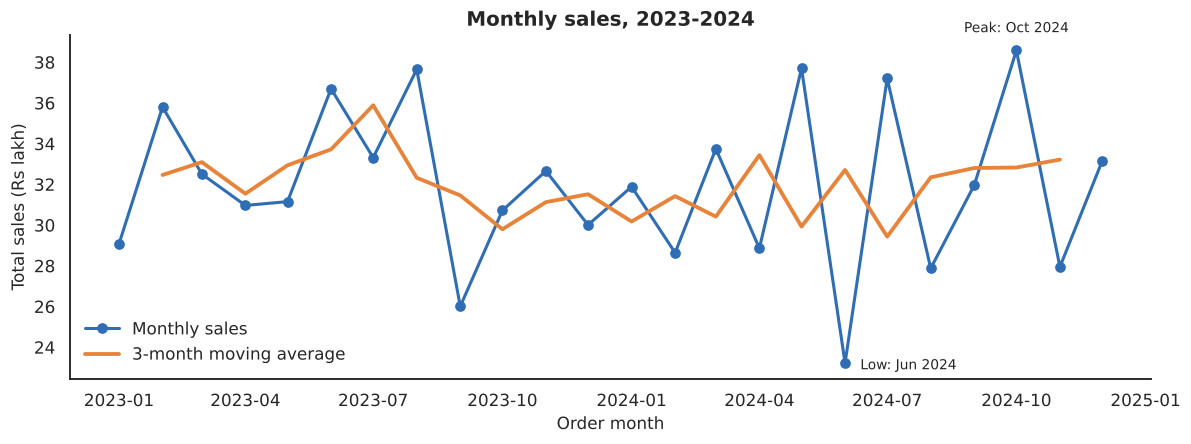

In [3]:
m = df.groupby('Order_Month').Sales.sum() / 1e5
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(m.index, m.values, color=BLUE, marker='o', lw=2, label='Monthly sales')
ax.plot(m.index, m.rolling(3, center=True).mean(), color=ORANGE, lw=2.5, label='3-month moving average')
hi_m, lo_m = m.idxmax(), m.idxmin()
ax.annotate(f'Peak: {hi_m:%b %Y}', (hi_m, m.max()), xytext=(0, 12), textcoords='offset points', ha='center', fontsize=9)
ax.annotate(f'Low: {lo_m:%b %Y}', (lo_m, m.min()), xytext=(10, -4), textcoords='offset points', ha='left', fontsize=9)
ax.set(title='Monthly sales, 2023-2024', xlabel='Order month', ylabel='Total sales (Rs lakh)'); ax.legend(frameon=False)
plt.tight_layout()
y23, y24 = df[df.Order_Date.dt.year == 2023].Sales.sum(), df[df.Order_Date.dt.year == 2024].Sales.sum()
CAP['c1'] = (f'Monthly sales range between Rs {m.min():.0f} and {m.max():.0f} lakh with no steady upward trend; the peak was {hi_m:%B %Y} and the low {lo_m:%B %Y}. '
             f'Full-year sales in 2024 were {abs(y24/y23-1)*100:.1f}% {"below" if y24 < y23 else "above"} 2023, so the business is flat rather than growing, and month-to-month swings are larger than any trend.')
print(CAP['c1'])

### Chart 2. Bar chart: total sales by region

East leads with Rs 2.00 crore and North is lowest at Rs 1.81 crore (highlighted), a gap of 11%. The four regions are close, so no region is failing; the lowest one is the natural place to look for the easiest extra growth.


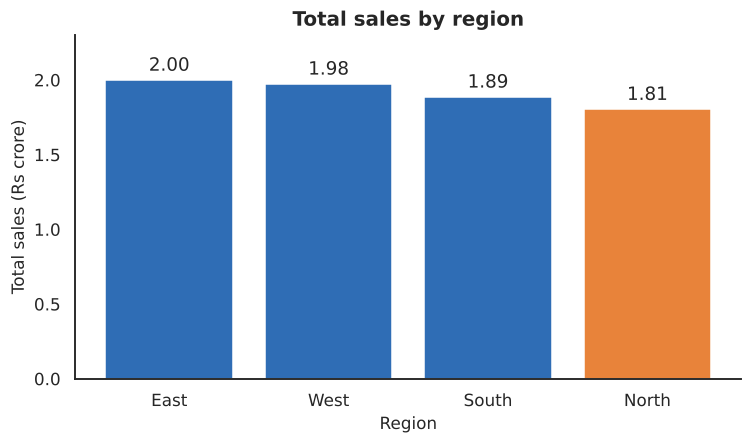

In [4]:
reg = df.groupby('Region').Sales.sum().sort_values(ascending=False) / 1e7
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(reg.index, reg.values, color=[ORANGE if r == reg.idxmin() else BLUE for r in reg.index])
ax.bar_label(bars, labels=[f'{v:.2f}' for v in reg.values], padding=3)
ax.set(title='Total sales by region', xlabel='Region', ylabel='Total sales (Rs crore)', ylim=(0, reg.max() * 1.15))
plt.tight_layout()
CAP['c2'] = (f'{reg.idxmax()} leads with Rs {reg.max():.2f} crore and {reg.idxmin()} is lowest at Rs {reg.min():.2f} crore (highlighted), a gap of {(reg.max()/reg.min()-1)*100:.0f}%. '
             f'The four regions are close, so no region is failing; the lowest one is the natural place to look for the easiest extra growth.')
print(CAP['c2'])

### Chart 3. Bar chart: total sales by product category

Electronics and Furniture together bring in 83% of all sales, while the other three categories add only 17%. Stock availability, pricing and promotion for these two categories matter far more to revenue than anything else the business sells.


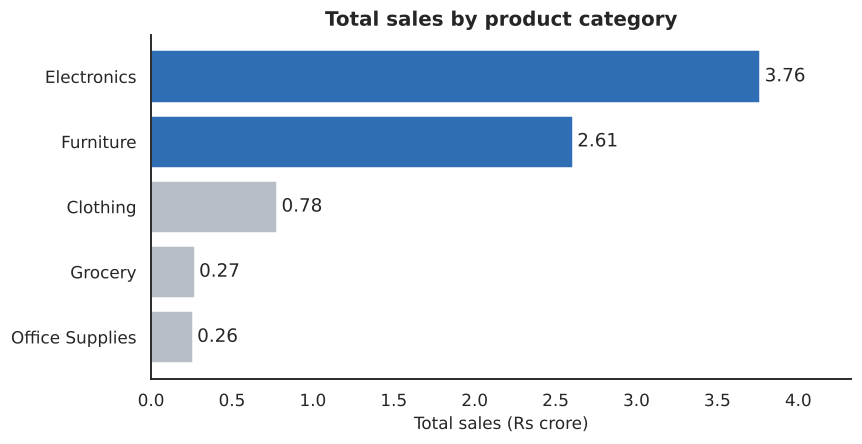

In [5]:
cat = df.groupby('Product_Category').Sales.sum().sort_values() / 1e7
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(cat.index, cat.values, color=[BLUE if v > 1 else GREY for v in cat.values])
ax.bar_label(bars, labels=[f'{v:.2f}' for v in cat.values], padding=3)
ax.set(title='Total sales by product category', xlabel='Total sales (Rs crore)', ylabel='', xlim=(0, cat.max() * 1.15))
plt.tight_layout()
top2 = cat.nlargest(2); share2 = top2.sum() / cat.sum() * 100
CAP['c3'] = (f'{top2.index[0]} and {top2.index[1]} together bring in {share2:.0f}% of all sales, while the other three categories add only {100-share2:.0f}%. '
             f'Stock availability, pricing and promotion for these two categories matter far more to revenue than anything else the business sells.')
print(CAP['c3'])

### Chart 4. Histogram: customer age

Age is almost symmetric (skewness 0.27): mean and median are both about 36. About 67% of transactions come from customers aged 25 to 45. Marketing aimed at working-age adults reaches the core customer base; customers above 60 are only 1.4% of transactions.


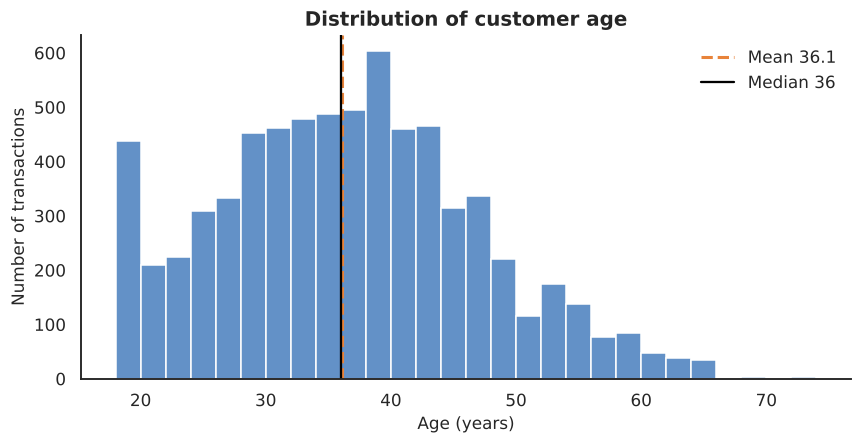

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(df.Age, bins=range(18, 76, 2), color=BLUE, ax=ax)
ax.axvline(df.Age.mean(), color=ORANGE, lw=2, ls='--', label=f'Mean {df.Age.mean():.1f}')
ax.axvline(df.Age.median(), color='black', lw=1.5, label=f'Median {df.Age.median():.0f}')
ax.set(title='Distribution of customer age', xlabel='Age (years)', ylabel='Number of transactions'); ax.legend(frameon=False)
plt.tight_layout()
share_25_45 = df.Age.between(25, 45).mean() * 100
CAP['c4'] = (f'Age is almost symmetric (skewness {df.Age.skew():.2f}): mean and median are both about {df.Age.median():.0f}. About {share_25_45:.0f}% of transactions come from customers aged 25 to 45. '
             f'Marketing aimed at working-age adults reaches the core customer base; customers above 60 are only {(df.Age > 60).mean()*100:.1f}% of transactions.')
print(CAP['c4'])

### Chart 5. Histogram: customer income

Income is strongly right-skewed (skewness 6.4): most customers earn near the median of Rs 48,847, while a few high earners pull the mean up to Rs 54,816. The chart hides the top 1% (above Rs 146,208) so the main body is readable. For typical-customer planning the median is the safer figure.


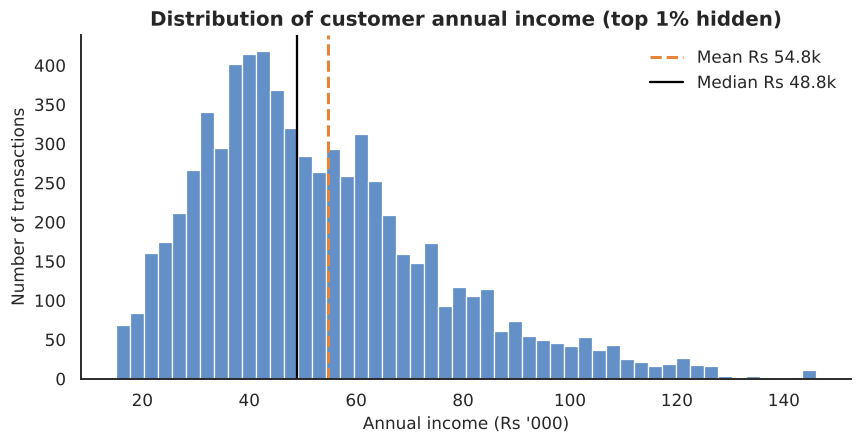

In [7]:
cut = df.Income.quantile(.99)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(df.Income[df.Income <= cut] / 1000, bins=50, color=BLUE, ax=ax)
ax.axvline(df.Income.mean() / 1000, color=ORANGE, lw=2, ls='--', label=f'Mean Rs {df.Income.mean()/1000:.1f}k')
ax.axvline(df.Income.median() / 1000, color='black', lw=1.5, label=f'Median Rs {df.Income.median()/1000:.1f}k')
ax.set(title='Distribution of customer annual income (top 1% hidden)', xlabel="Annual income (Rs '000)", ylabel='Number of transactions'); ax.legend(frameon=False)
plt.tight_layout()
CAP['c5'] = (f'Income is strongly right-skewed (skewness {df.Income.skew():.1f}): most customers earn near the median of Rs {df.Income.median():,.0f}, while a few high earners pull the mean up to Rs {df.Income.mean():,.0f}. '
             f'The chart hides the top 1% (above Rs {cut:,.0f}) so the main body is readable. For typical-customer planning the median is the safer figure.')
print(CAP['c5'])

### Chart 6. Box plot: sales spread by product category

Typical order value differs hugely by category: the median Furniture order is Rs 21,490 against Rs 1,324 for Grocery, about 16 times larger. A log scale is used so all five boxes are visible. Every category has some very large orders (dots above the whiskers), so category averages are lifted by a few big purchases.


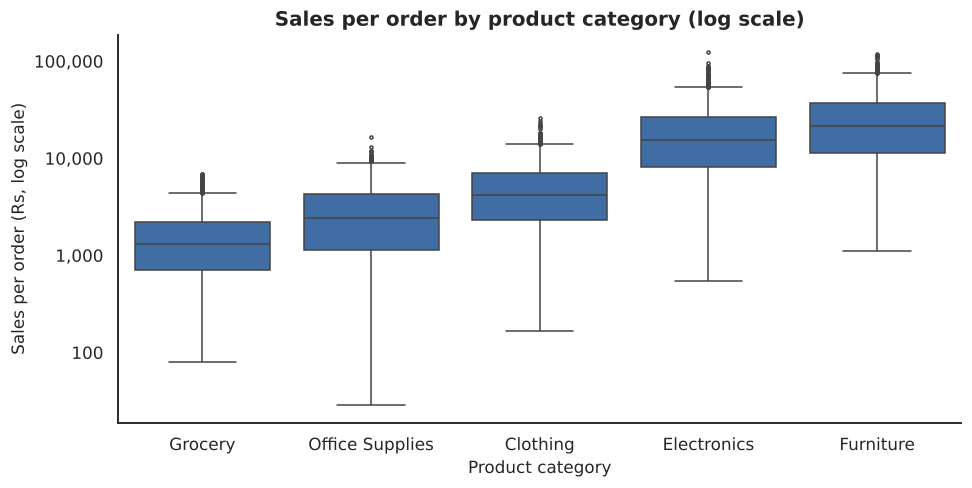

In [8]:
order = df.groupby('Product_Category').Sales.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.boxplot(data=df, x='Product_Category', y='Sales', order=order, color=BLUE, fliersize=2, linewidth=1, ax=ax)
ax.set_yscale('log')
ax.set(title='Sales per order by product category (log scale)', xlabel='Product category', ylabel='Sales per order (Rs, log scale)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout()
med = df.groupby('Product_Category').Sales.median()
CAP['c6'] = (f'Typical order value differs hugely by category: the median {med.idxmax()} order is Rs {med.max():,.0f} against Rs {med.min():,.0f} for {med.idxmin()}, about {med.max()/med.min():.0f} times larger. '
             f'A log scale is used so all five boxes are visible. Every category has some very large orders (dots above the whiskers), so category averages are lifted by a few big purchases.')
print(CAP['c6'])

### Chart 7. Scatter plot: sales vs profit

Profit rises almost in a straight line with sales (correlation 0.97); each extra rupee of sales adds about 33 paise of profit. This tight pattern shows margins are very consistent across orders, so profit is driven by how much is sold, not by wide differences in pricing between orders.


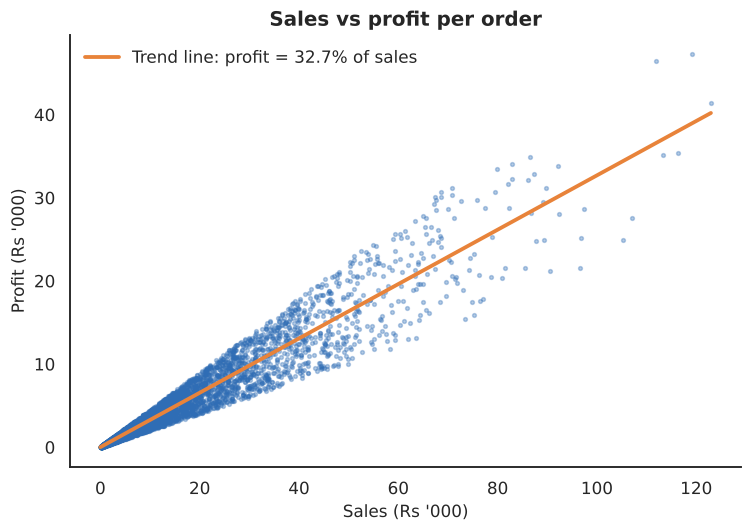

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.Sales / 1e3, df.Profit / 1e3, s=6, alpha=.35, color=BLUE)
slope, icpt = np.polyfit(df.Sales, df.Profit, 1)
xs = np.linspace(0, df.Sales.max(), 50)
ax.plot(xs / 1e3, (icpt + slope * xs) / 1e3, color=ORANGE, lw=2.5, label=f'Trend line: profit = {slope*100:.1f}% of sales')
ax.set(title='Sales vs profit per order', xlabel="Sales (Rs '000)", ylabel="Profit (Rs '000)"); ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
r = df.Sales.corr(df.Profit)
CAP['c7'] = (f'Profit rises almost in a straight line with sales (correlation {r:.2f}); each extra rupee of sales adds about {slope*100:.0f} paise of profit. '
             f'This tight pattern shows margins are very consistent across orders, so profit is driven by how much is sold, not by wide differences in pricing between orders.')
print(CAP['c7'])

### Chart 8. Scatter plot: discount vs profit

There is only a weak negative link between discount and profit (correlation -0.12): bigger discounts go with somewhat smaller profits per order, but the points are widely scattered. Discount level explains very little of the variation in profit, so cutting discounts alone would not be a reliable way to raise profit. A sample is plotted for readability; the trend line uses all orders.


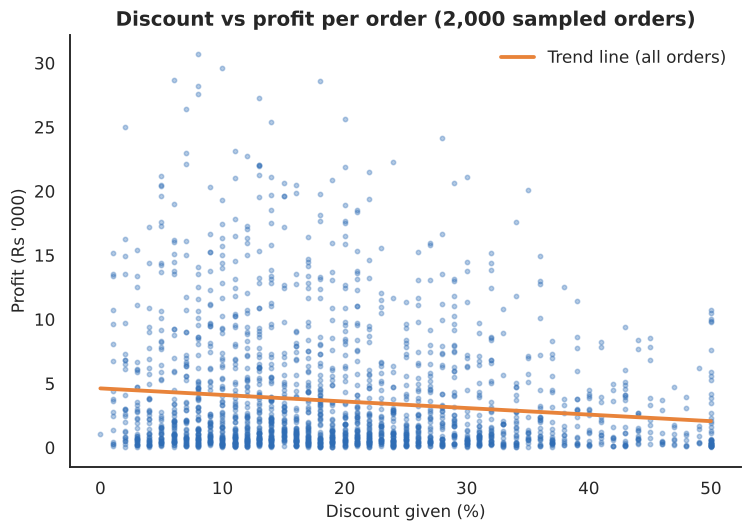

In [10]:
samp = df.sample(2000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(samp.Discount * 100, samp.Profit / 1e3, s=8, alpha=.35, color=BLUE)
s2, i2 = np.polyfit(df.Discount, df.Profit, 1); xs = np.linspace(0, .5, 50)
ax.plot(xs * 100, (i2 + s2 * xs) / 1e3, color=ORANGE, lw=2.5, label='Trend line (all orders)')
ax.set(title='Discount vs profit per order (2,000 sampled orders)', xlabel='Discount given (%)', ylabel="Profit (Rs '000)"); ax.legend(frameon=False)
plt.tight_layout()
r2 = df.Discount.corr(df.Profit)
CAP['c8'] = (f'There is only a weak negative link between discount and profit (correlation {r2:.2f}): bigger discounts go with somewhat smaller profits per order, but the points are widely scattered. '
             f'Discount level explains very little of the variation in profit, so cutting discounts alone would not be a reliable way to raise profit. A sample is plotted for readability; the trend line uses all orders.')
print(CAP['c8'])

### Chart 9. Donut chart: share of sales by customer segment

Consumer customers account for 54% of sales, Corporate for 31% and Home Office for 15%. Consumers are the largest group by volume, but Corporate and Home Office together make up 46% of sales, which is a meaningful base for business-focused offers.


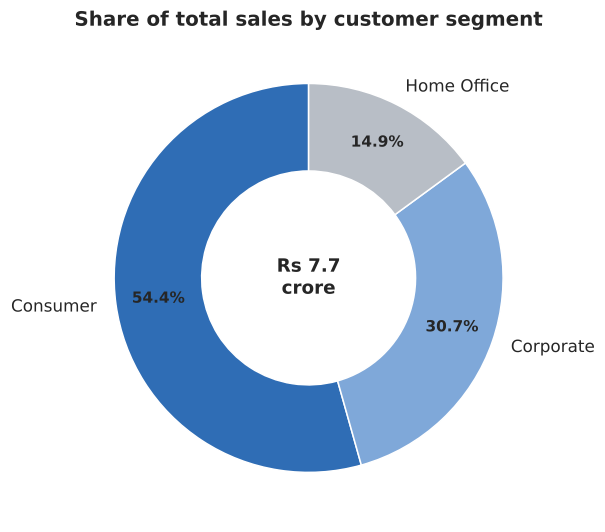

In [11]:
seg = df.groupby('Customer_Segment').Sales.sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 5))
w, t, a = ax.pie(seg.values, labels=seg.index, colors=SEG_COLORS, autopct='%1.1f%%', startangle=90, pctdistance=.78,
                 wedgeprops=dict(width=.45, edgecolor='white'), textprops={'fontsize': 11})
for x in a: x.set_fontsize(10); x.set_fontweight('bold')
ax.set_title('Share of total sales by customer segment'); ax.text(0, 0, f'Rs {seg.sum()/1e7:.1f}\ncrore', ha='center', va='center', fontsize=12, fontweight='bold')
plt.tight_layout()
sh = seg / seg.sum() * 100
CAP['c9'] = (f'{sh.index[0]} customers account for {sh.iloc[0]:.0f}% of sales, {sh.index[1]} for {sh.iloc[1]:.0f}% and {sh.index[2]} for {sh.iloc[2]:.0f}%. '
             f'Consumers are the largest group by volume, but Corporate and Home Office together make up {sh.iloc[1]+sh.iloc[2]:.0f}% of sales, which is a meaningful base for business-focused offers.')
print(CAP['c9'])

### Chart 10. Heatmap: correlation matrix

Sales and Profit move together almost perfectly (0.97), and Quantity has a moderate link with Sales (0.37). Customer Age and Income have almost no relationship with Sales (both within 0.01), so who the customer is does not predict how much they spend. Correlation shows association only, not cause.


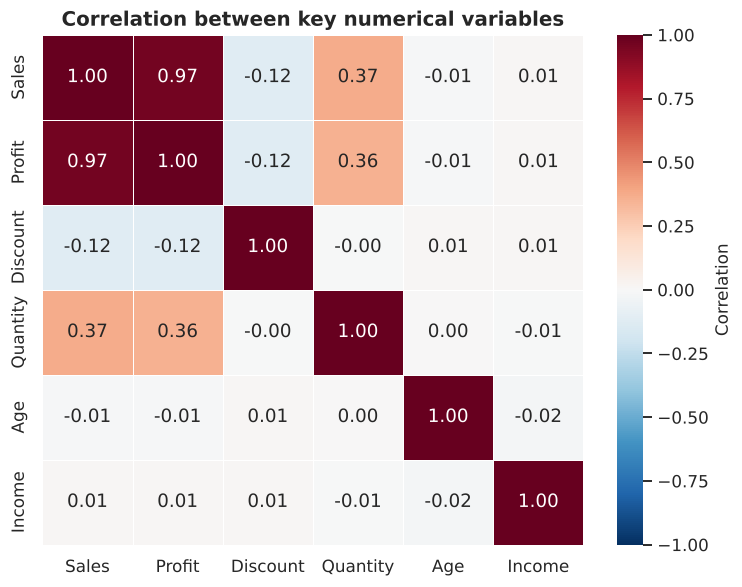

In [12]:
cols = ['Sales', 'Profit', 'Discount', 'Quantity', 'Age', 'Income']
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={'label': 'Correlation'}, ax=ax)
ax.set_title('Correlation between key numerical variables'); plt.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
pairs_nonsp = pairs.drop(('Sales', 'Profit'))
b = pairs_nonsp.abs().sort_values(ascending=False)
CAP['c10'] = (f'Sales and Profit move together almost perfectly ({corr.loc["Sales", "Profit"]:.2f}), and Quantity has a moderate link with Sales ({corr.loc["Sales", "Quantity"]:.2f}). '
              f'Customer Age and Income have almost no relationship with Sales (both within {max(abs(corr.loc["Sales", "Age"]), abs(corr.loc["Sales", "Income"])):.2f}), so who the customer is does not predict how much they spend. Correlation shows association only, not cause.')
print(CAP['c10'])

### Chart 11. Heatmap: average sales by category and region

The category matters much more than the region: within any region the best category is at least 15 times the weakest, while within any category the best region is at most 1.1 times the weakest. The highest cell is Furniture in the West (Rs 27,370 per order) and the lowest is Grocery in the North (Rs 1,558). Regional strategy can be uniform; category mix is the real lever.


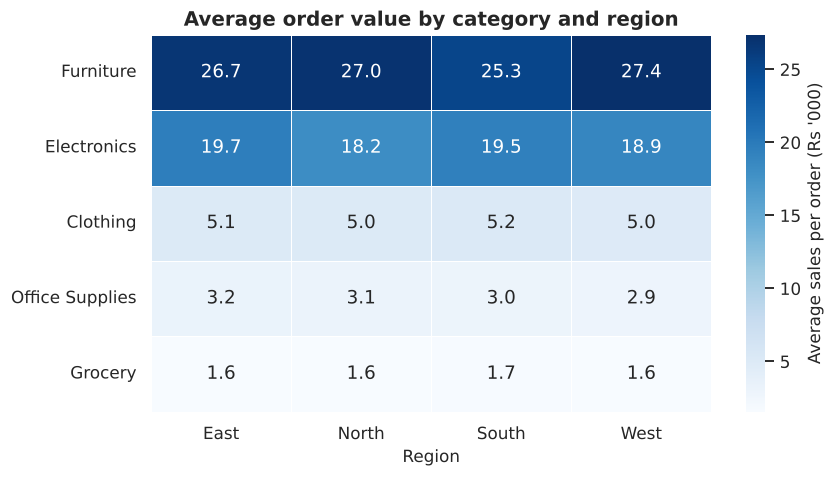

In [13]:
pv = df.pivot_table(index='Product_Category', columns='Region', values='Sales', aggfunc='mean')
pv = pv.loc[pv.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pv / 1000, annot=True, fmt='.1f', cmap='Blues', linewidths=.5, cbar_kws={'label': "Average sales per order (Rs '000)"}, ax=ax)
ax.set(title='Average order value by category and region', xlabel='Region', ylabel=''); plt.tight_layout()
flat = pv.stack(); cmax, cmin = flat.idxmax(), flat.idxmin()
row_spread = (pv.max(axis=1) / pv.min(axis=1)).max(); col_spread = (pv.max(axis=0) / pv.min(axis=0)).min()
CAP['c11'] = (f'The category matters much more than the region: within any region the best category is at least {col_spread:.0f} times the weakest, while within any category the best region is at most {row_spread:.1f} times the weakest. '
              f'The highest cell is {cmax[0]} in the {cmax[1]} (Rs {flat.max():,.0f} per order) and the lowest is {cmin[0]} in the {cmin[1]} (Rs {flat.min():,.0f}). Regional strategy can be uniform; category mix is the real lever.')
print(CAP['c11'])

### Chart 12. Bar chart: return rate by product category

About 12.6% of all orders (roughly 1 in 8) are returned. Clothing has the highest rate at 13.5% and Office Supplies the lowest at 11.5%, a spread of only 2.0 points. Returns are a business-wide issue rather than a problem in one category, so fixes should target the whole order and delivery process.


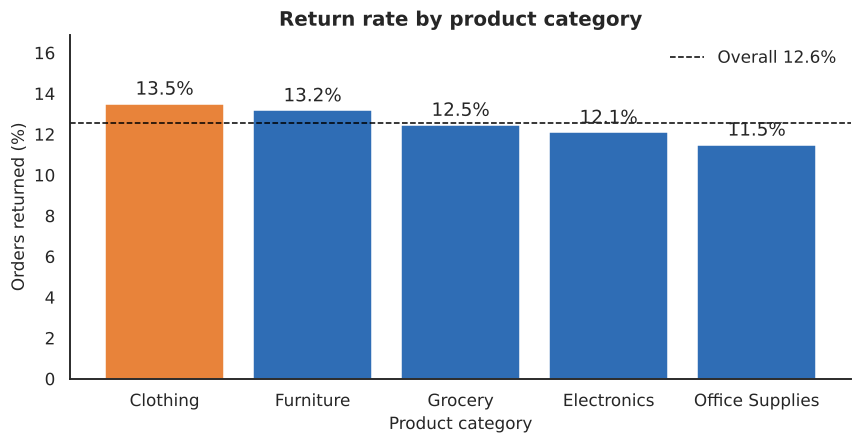

In [14]:
rr = df.groupby('Product_Category').Returned_Flag.mean().mul(100).sort_values(ascending=False)
overall = df.Returned_Flag.mean() * 100
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(rr.index, rr.values, color=[ORANGE if v == rr.max() else BLUE for v in rr.values])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in rr.values], padding=3)
ax.axhline(overall, color='black', ls='--', lw=1, label=f'Overall {overall:.1f}%')
ax.set(title='Return rate by product category', xlabel='Product category', ylabel='Orders returned (%)', ylim=(0, rr.max() * 1.25)); ax.legend(frameon=False)
plt.tight_layout()
CAP['c12'] = (f'About {overall:.1f}% of all orders (roughly 1 in 8) are returned. {rr.index[0]} has the highest rate at {rr.max():.1f}% and {rr.index[-1]} the lowest at {rr.min():.1f}%, a spread of only {rr.max()-rr.min():.1f} points. '
              f'Returns are a business-wide issue rather than a problem in one category, so fixes should target the whole order and delivery process.')
print(CAP['c12'])

## 3. Chart Checklist
| Required type | Chart(s) |
|---|---|
| Line chart | 1 |
| Bar chart | 2, 3, 12 |
| Histogram | 4, 5 |
| Box plot | 6 |
| Scatter plot | 7, 8 |
| Pie / donut | 9 |
| Heatmap | 10, 11 |

12 charts in total. The captions are saved to `captions.json`, which feeds the compiled visual report.

In [15]:
json.dump(CAP, open('captions.json', 'w'), indent=1)
print('Charts with captions:', len(CAP))

Charts with captions: 12
